## Test 1

In [ ]:
from pathlib import Path
from pprint import pprint


def load_fasta(path):
    records = []
    current_record = None

    with open(path, "r", encoding="utf-8") as file:
        for line in file:
            line = line.strip()

            # 跳过空行
            if not line:
                continue

            if line.startswith(">"):
                # 去掉 >，再按 | 拆分标题
                fields = line[1:].split("|")

                current_record = {
                    "accession": fields[0].strip(),
                    "allele": fields[1].strip(),
                    "species": fields[2].strip(),
                    "functionality": fields[3].strip(),
                    "region": fields[4].strip(),
                    "sequence": "",
                }

                records.append(current_record)

            else:
                # 把多行序列连接到当前记录中
                if current_record is None:
                    raise ValueError("文件格式错误：序列前缺少标题")

                current_record["sequence"] += line

    return records

In [6]:
path = "reference.fasta"

# 读取全部记录
records = load_fasta(path)
# 查看读取结果
print("记录总数：", len(records))

if records:
    print("\n第一条记录：")
    pprint(records[0], sort_dicts=False)

记录总数： 17481

第一条记录：
{'accession': 'KT723008',
 'allele': 'IGHA*01',
 'species': 'Bos taurus_Holstein',
 'functionality': 'F',
 'region': 'CH1',
 'sequence': '....XSETSPSIFPLSLGNNDP....AGQVVIGCLVQGFFPS.APLSVTWNQNGDSV....SVRNFPAVLAGS.......LYTMSSQLTLPASLC..PKGQSVTCQVQHL...SKASKTVAVPCIIQ'}


In [7]:
import csv

results = []

for record in records:
    # 1. 筛选人类 TR 的 V 区记录
    if record["species"] != "Homo sapiens":
        continue

    if not record["allele"].startswith("TR"):
        continue

    if record["region"] != "V-REGION":
        continue

    # 2. 获取完整的带缺口序列
    sequence = record["sequence"]

    # 3. 切片，再去掉片段中的点号
    # CDR1：第 27–38 位
    # CDR2：第 56–65 位
    cdr1 = sequence[26:38].replace(".", "")
    cdr2 = sequence[55:65].replace(".", "")

    results.append({
        "allele": record["allele"],
        "cdr1": cdr1,
        "cdr2": cdr2,
    })

if any(row["cdr1"] is Ellipsis or row["cdr2"] is Ellipsis
       for row in results):
    raise ValueError("请先填写 CDR1 和 CDR2 的切片")

output_path = "cdr_sequences.tsv"

with open(output_path, "w", encoding="utf-8", newline="") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=["allele", "cdr1", "cdr2"],
        delimiter="\t",
    )
    writer.writeheader()
    writer.writerows(results)

print("输出记录数：", len(results))
print("保存位置：", output_path)

输出记录数： 385
保存位置： cdr_sequences.tsv


## Test 2

In [ ]:
from Bio import Entrez

# 填写你的真实邮箱
Entrez.email = "tan19991103@outlook.com"

query = (
    'medulloblastoma '
    'AND Shih[Author] '
    'AND ("2010/01/01"[Date - Publication] : '
    '"2020/12/31"[Date - Publication])'
)

total = 1000
with Entrez.esearch(
    db="pubmed",
    term=query,
    retmax=total,
) as handle:
    search_result = Entrez.read(handle)

pmids = search_result["IdList"]

print("获取的 PMID 数量：", len(pmids))

获取的 PMID 数量： 40


In [ ]:
# 获取检索结果中的全部编号

with Entrez.efetch(
    db="pubmed",
    id=",".join(pmids),
    retmode="xml",
) as handle:
    papers = Entrez.read(handle)

print("获取的文献数量：", len(papers["PubmedArticle"]))

获取的文献数量： 40


In [13]:
records = []

for paper in papers["PubmedArticle"]:
    citation = paper["MedlineCitation"]
    article = citation["Article"]

    abstract_parts = article.get("Abstract", {}).get("AbstractText", [])

    records.append({
        "pmid": str(citation["PMID"]),
        "title": str(article["ArticleTitle"]),
        "abstract": "\n".join(str(part) for part in abstract_parts),
    })

print("整理后的数量：", len(records))

if records:
    print(records[0])

整理后的数量： 40
{'pmid': '29856958', 'title': 'A Hematogenous Route for Medulloblastoma Leptomeningeal Metastases.', 'abstract': ''}


In [14]:
import csv

with open("papers.csv", "w", encoding="utf-8", newline="") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=["pmid", "title", "abstract"],
    )
    writer.writeheader()
    writer.writerows(records)

print(f"已保存 {len(records)} 篇文献到 papers.csv")

已保存 40 篇文献到 papers.csv


In [15]:
import csv
import sqlite3

# 从 CSV 读取数据
with open("papers.csv", "r", encoding="utf-8", newline="") as file:
    rows = list(csv.DictReader(file))

connection = sqlite3.connect("pubmed_shih_2010_2020.db")

try:
    with connection:
        connection.execute("""
            CREATE TABLE IF NOT EXISTS papers (
                pmid TEXT PRIMARY KEY,
                title TEXT,
                abstract TEXT
            )
        """)

        connection.executemany("""
            INSERT OR REPLACE INTO papers (pmid, title, abstract)
            VALUES (:pmid, :title, :abstract)
        """, rows)

    count = connection.execute(
        "SELECT COUNT(*) FROM papers"
    ).fetchone()[0]

    print("CSV 记录数：", len(rows))
    print("数据库记录数：", count)

finally:
    connection.close()

CSV 记录数： 40
数据库记录数： 40


In [20]:
import sqlite3
import re

connection = sqlite3.connect("pubmed_shih_2010_2020.db")

try:
    candidates = connection.execute("""
        SELECT pmid, title, abstract
        FROM papers
        WHERE abstract LIKE ?
    """, ("%MYC%",)).fetchall()

finally:
    connection.close()
confirmed_pmids = []

for pmid, title, abstract in candidates:
    if re.search(r"\bMYC\b", abstract, flags=re.IGNORECASE):
        confirmed_pmids.append(pmid)

print("匹配数量：", len(confirmed_pmids))
print("PMID：", confirmed_pmids)

匹配数量： 4
PMID： ['28504719', '25739120', '24493713', '22832581']


In [ ]:
import csv
import sqlite3

if len(confirmed_pmids) != len(set(confirmed_pmids)):
    raise ValueError("PMID 列表有重复")

connection = sqlite3.connect("pubmed_shih_2010_2020.db")

try:
    results = []

    for pmid in confirmed_pmids:
        row = connection.execute(
            "SELECT pmid, title FROM papers WHERE pmid = ?",
            (pmid,),
        ).fetchone()

        if row is None:
            raise ValueError(f"数据库中找不到 PMID：{pmid}")

        results.append(row)

finally:
    connection.close()

with open("myc_papers.tsv", "w", encoding="utf-8", newline="") as file:
    writer = csv.writer(file, delimiter="\t")
    writer.writerow(["pmid", "title"])
    writer.writerows(results)

print(f"已导出 {len(results)} 篇文献到 myc_papers.tsv")

已导出 4 篇文献到 myc_papers.tsv


## Test 3 最终固定模型
最终模型为 MLM260 后联合训练的第40轮检查点，采用 CLS 与线性分类头。
此节可独立运行，默认只读取已完成的评价，不重新训练或重新选择模型。

完整测试集准确率58.71%；IG/TR测试子集57.68%、Macro F1 0.3749。
注意：历史训练含469条非IG/TR记录，未按IG/TR过滤；这是已记录的数据范围限制，不能称为严格IG/TR专用训练。


In [1]:
from pathlib import Path
import json
from IPython.display import Image, display, FileLink
from dna_training import ExperimentConfig, load_prepared, load_model

PROJECT = Path.cwd()
assert (PROJECT / "final_model/model.pt").exists(), "请在项目根目录运行 Notebook"
config = ExperimentConfig.load(PROJECT / "configs/final.json")
model, checkpoint = load_model(PROJECT / "final_model/model.pt", device="auto")
print("固定模型轮次：", checkpoint["epoch"])
print("编码器配置：", checkpoint["model_config"])
print("参数量：", sum(p.numel() for p in model.parameters()))
print("设备：", next(model.parameters()).device)


固定模型轮次： 40
编码器配置： {'d_model': 256, 'nhead': 8, 'num_layers': 2, 'dim_feedforward': 1024, 'dropout': 0.1, 'max_length': 512}
参数量： 1655721
设备： mps:0


### 固定数据和 BPE
复用历史划分与训练集词表，不重新分词训练或改变标签。
原始FASTA保留用于复核；最终推理输入是每条记录的全部碱基，而不是完整基因组。


In [2]:
prepared_path = PROJECT / "prepared/datasets/d3063cc3fdc7a7ad6a1ff16921701375136a0a2c157cc869a1ec5ecaf1c07f34"
prepared = load_prepared(prepared_path)
tokenizer = prepared.tokenizer
label_to_id = prepared.label_to_id
print("训练 / 验证 / 测试：", len(prepared.train_records), len(prepared.val_records), len(prepared.test_records))
print("类别 / 词表：", len(label_to_id), len(tokenizer.token_to_id))
assert label_to_id == checkpoint["label_to_id"]
print("数据范围：", json.loads((PROJECT / "scope_audit.json").read_text()))


训练 / 验证 / 测试： 14360 1780 1780
类别 / 词表： 41 128
数据范围： {'training': {'IG': 9068, 'TR': 4823, 'other': 469}, 'validation': {'IG': 1128, 'TR': 592, 'other': 60}, 'test': {'IG': 1125, 'TR': 593, 'other': 62}, 'policy': 'Original model and split frozen. IG/TR evaluation subset defined by task gene scope, without retraining or checkpoint reselection.'}


### 查看已经完成的最终测试
完整测试集和按题目范围提取的IG/TR子集分别保存，不能混用样本数和指标。
这里读取保存结果，不触发新的测试推理。混淆矩阵每行为预测类别，每列为真实类别。


final_test 样本数： 1780 准确率： 58.71% Macro F1： 0.3796
final_test_igtr 样本数： 1718 准确率： 57.68% Macro F1： 0.3749


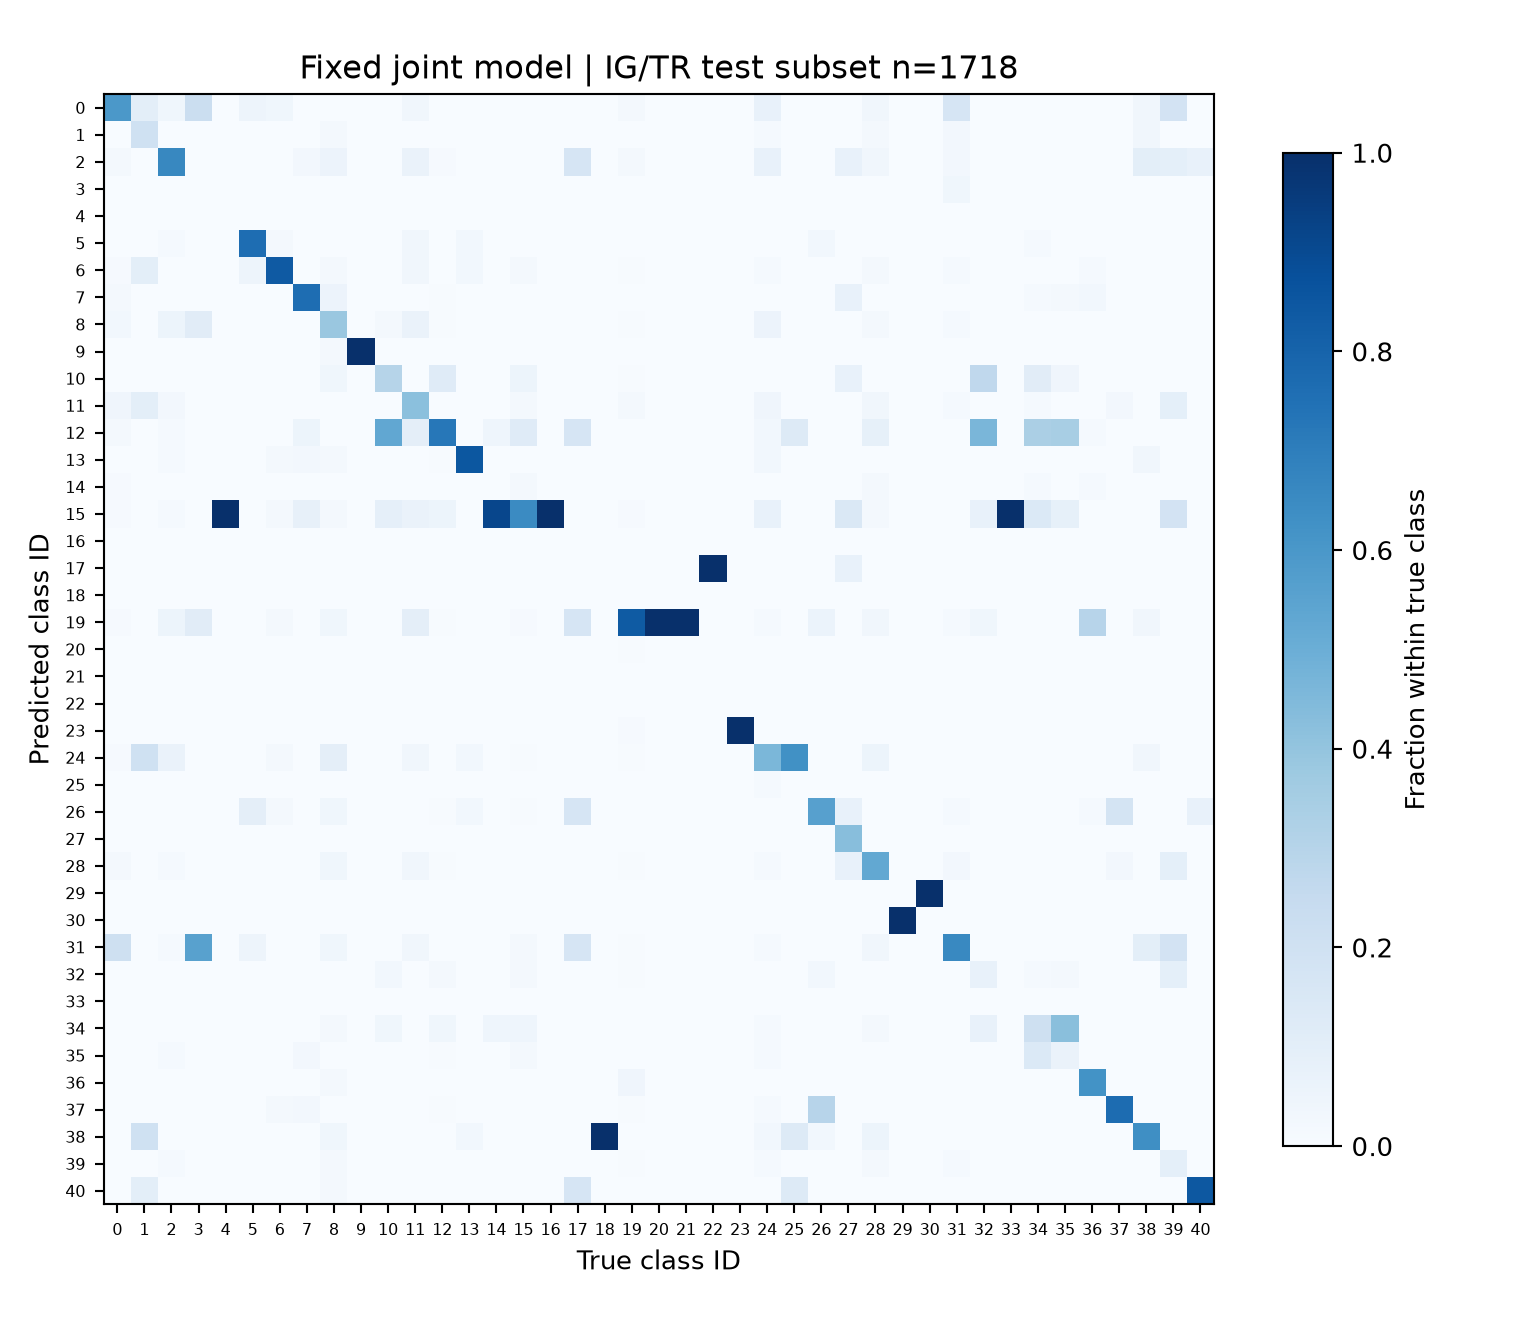

In [3]:
for name in ["final_test", "final_test_igtr"]:
    metrics = json.loads((PROJECT / name / "metrics.json").read_text())
    print(name, "样本数：", metrics["samples"],
          "准确率：", f"{metrics['accuracy']:.2%}",
          "Macro F1：", f"{metrics['macro_f1']:.4f}")
display(Image(filename=str(PROJECT / "reports/figures/test_igtr_confusion.png")))


### 查看最终联合训练曲线和报告
曲线读取原始逐轮记录。可在项目根目录运行 `tensorboard --logdir runs --port 6006`，筛选 `final`。


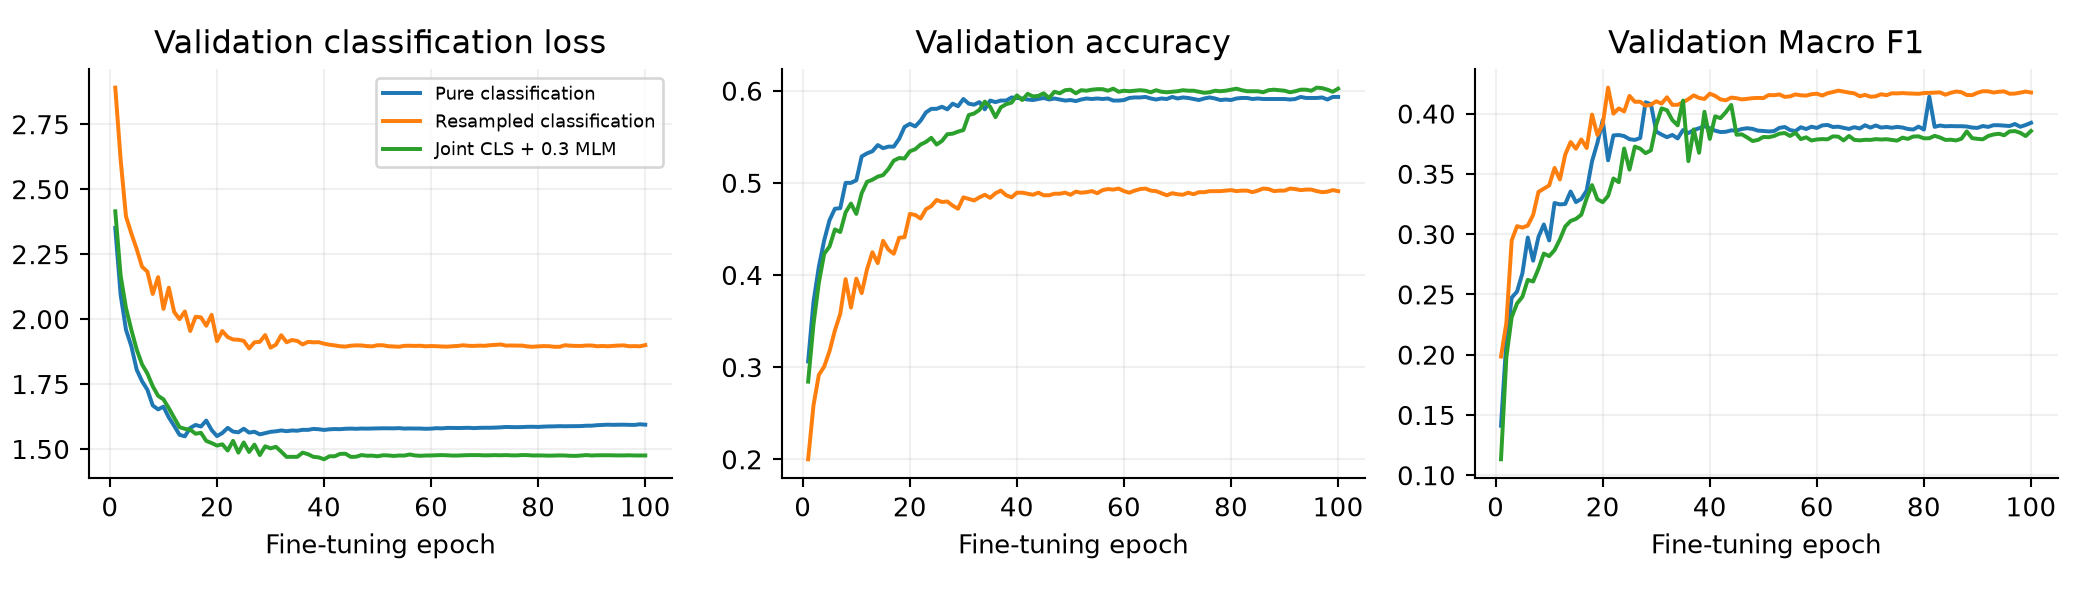

/Users/pt623/Desktop/david-shih-python-exercises/reports/DNA物种分类训练与调优报告.pdf

In [4]:
display(Image(filename=str(PROJECT / "reports/figures/mlm260_comparison.png")))
display(FileLink(str(PROJECT / "reports/DNA物种分类训练与调优报告.pdf")))


### 可选 重新训练同一方案
默认关闭。打开后将从保留的MLM260初始化权重创建新实验，不修改固定最终模型，也不自动重新评价测试集。
这是历史混合基因数据方案的复现；若要严格限制IG/TR，需要另立新的数据与实验协议。


In [5]:
RUN_TRAINING = False
if RUN_TRAINING:
    from dna_training import run_experiment
    result = run_experiment(
        prepared, config,
        init_from=PROJECT / "final_model/mlm_pretrained.pt",
    )
    print("新实验目录：", result.run_dir)
    print("最佳检查点：", result.best_checkpoint)
else:
    print("训练未启动；固定模型与测试结果保持不变。")


训练未启动；固定模型与测试结果保持不变。
